# Wykład 12 — Od zmiennych do własnych typów danych. Struktury w C

Dwa roboty mają nazwy, położenia i prędkości. Jak zapisać ich stan, żeby przesunięcie jednego z nich nie zmieniło danych drugiego? Zaczniemy od tablic, zbudujemy własny typ, a na końcu połączymy osobno utworzone obiekty w listę.

Uruchamiaj eksperymenty w kernelu **C**. Każda komórka z kodem zawiera cały program. Przed uruchomieniem spróbuj przewidzieć wynik.

## W12.1 — Gdy sześć tablic nie wystarcza

W tablicach równoległych wspólny indeks identyfikuje robota. Nazwa `name[i]`, pozycja `x[i], y[i]`, prędkość `vx[i], vy[i]` oraz przyspieszenie `ax[i], ay[i]` muszą dotyczyć tego samego obiektu. Jeśli przestawisz nazwy i współrzędne niezależnie, roboty zamienią się danymi. Funkcje grupują działanie, a struktury grupują dane.

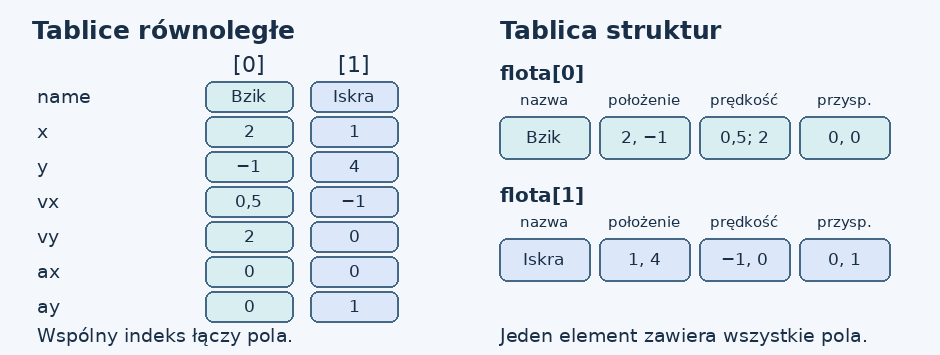

**Przewidź.** Które elementy tablic dotyczą Iskry? Jaka będzie jej pozycja po zmianie prędkości i kroku ruchu o jedną sekundę?

In [ ]:
#include <stdio.h>

int main(void)
{
    enum { N = 2 };
    const char name[N][50] = {"Bzik", "Iskra"};
    double x[N] = {2.0, 1.0}, y[N] = {-1.0, 4.0};
    double vx[N] = {0.5, -1.0}, vy[N] = {2.0, 0.0};
    const double ax[N] = {0.0, 0.0}, ay[N] = {0.0, 1.0};
    const double dt = 1.0;
    const int i = 1;

    vx[i] += ax[i] * dt;
    vy[i] += ay[i] * dt;
    x[i] += vx[i] * dt;
    y[i] += vy[i] * dt;

    printf("%s: (%.1f, %.1f)\n", name[0], x[0], y[0]);
    printf("%s: (%.1f, %.1f)\n", name[i], x[i], y[i]);
    return 0;
}

Bzik pozostał w `(2, −1)`. U Iskry zmieniliśmy najpierw prędkość, a potem użyliśmy jej do obliczenia nowego położenia `(0, 5)`. Wszystkie cztery przypisania musiały użyć tego samego indeksu.

**Zmień.** Ustaw `i = 0` i sprawdź swoją prognozę. Jakie dane musisz przenieść razem, jeśli chcesz zamienić miejscami oba roboty w tablicach?

## W12.2 — Tworzymy własny typ

Robot potrzebuje pól różnych typów. Tablica przechowuje elementy jednego typu, a struktura pozwala połączyć w jednym obiekcie nazwę i kilka liczb. Definicja `struct Robot { … };` opisuje typ. Deklaracja `struct Robot robot;` tworzy obiekt tego typu. `typedef struct Robot Robot;` daje krótszą nazwę tego samego typu.

Inicjalizacja pozycyjna używa kolejności pól z definicji. Inicjalizacja z nazwanymi polami wskazuje przeznaczenie każdej wartości, a pominięte pola liczbowe dostają zero. W `char name[50]` trzeba zmieścić bajty nazwy i znak końca napisu `'\0'`.

**Przewidź.** Które napisy zobaczysz po przypisaniu całej struktury i zmianie pierwszej litery oryginału?

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y, vx, vy;
};

typedef struct Robot Robot;

int main(void)
{
    struct Robot first = {"Bzik", 2.0, -1.0, 0.5, 2.0};
    Robot second = {.name = "Iskra", .x = 1.0, .y = 4.0, .vx = -1.0};

    printf("Przed kopią: %s i %s\n", first.name, second.name);
    second = first;
    first.name[0] = 'D';
    first.x = 8.0;

    printf("Oryginał: %s (%.1f, %.1f)\n", first.name, first.x, first.y);
    printf("Kopia: %s (%.1f, %.1f)\n", second.name, second.x, second.y);
    return 0;
}

Przypisanie zgodnych struktur kopiuje wartości wszystkich pól, w tym zawartość `name`. Po deklaracji zapis `second.name = "Iskra"` jest błędem, ponieważ sama tablica nie jest przypisywalna. Możesz zmienić jej elementy lub skopiować napis do bufora o odpowiedniej pojemności. Gdy pole ma typ wskaźnikowy, przypisanie kopiuje adres. Obie kopie takiego pola mogą wtedy wskazywać te same dane.

**Zmień.** Zainicjalizuj `first` przez nazwane pola. Czy wynik się zmieni?

**Sprawdź.** Zaprojektuj `struct Student` z imieniem, nazwiskiem, numerem albumu i oceną. Utwórz dwa obiekty, skopiuj jeden do drugiego i sprawdź, czy zmiana oceny w oryginale zmienia ocenę w kopii.

## W12.3 — Dostęp do pól

Mając robota `r`, czytasz jego pole przez `r.x`. Gdy `p = &r`, strzałka w `p->x` łączy dwa kroki: odwołaj się do obiektu pod adresem (`*p`), a następnie wybierz pole (`.x`). W zapisie `(*p).x` nawiasy wymuszają tę kolejność.

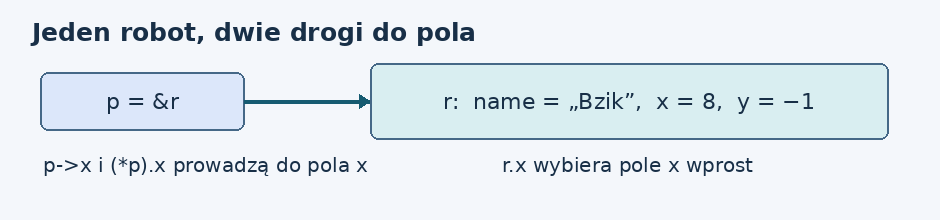

**Przewidź.** Co pokażą trzy zapisy po przypisaniu do `p->x`?

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y;
};

int main(void)
{
    struct Robot r = {.name = "Bzik", .x = 2.0, .y = -1.0};
    struct Robot *p = &r;

    p->x = 8.0;
    printf("%s: %.1f %.1f %.1f\n", r.name, r.x, p->x, (*p).x);
    return 0;
}

Wszystkie trzy wyrażenia odczytały `8.0`. Wskaźnik zawiera adres obiektu, więc zmiana przez strzałkę jest widoczna także przez kropkę.

**Zmień.** Przypisz `5.0` do pola `y` przez zapis z dereferencją i kropką. Wypisz je przez strzałkę.

**Znajdź błąd.** Dlaczego `p.x`, `r->x` i `*p.x` są błędne przy powyższych deklaracjach? Co się stanie z możliwością dostępu przez `p->x`, gdy `p` ma wartość `NULL`?

## W12.4 — Struktura w pamięci

Kolejność deklaracji wyznacza kolejność pól w pamięci. Kompilator może wstawić pomiędzy nimi i na końcu przerwy (ang. *padding*), między innymi po to, by umieścić pola i kolejne elementy tablicy struktur pod odpowiednio wyrównanymi adresami. `sizeof` mierzy rozmiar całego obiektu w bajtach, a `offsetof` podaje przesunięcie pola od początku struktury.

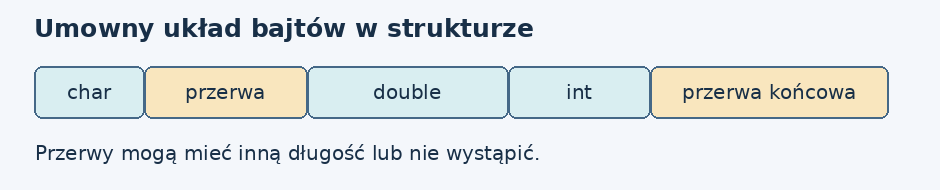

**Przewidź.** Czy suma rozmiarów pól wystarczy do ustalenia rozmiaru struktury? Uruchom pomiar na platformie, na której działa Twój kernel C.

In [ ]:
#include <stddef.h>
#include <stdio.h>

struct Measurement {
    char code;
    double value;
    int count;
};

int main(void)
{
    struct Measurement reading = {.code = 'A', .value = 2.5, .count = 3};
    struct Measurement *p = &reading;

    printf("obiekt=%zu wskaznik=%zu\n", sizeof reading, sizeof p);
    printf("code: offset=%zu rozmiar=%zu\n",
           offsetof(struct Measurement, code), sizeof reading.code);
    printf("value: offset=%zu rozmiar=%zu\n",
           offsetof(struct Measurement, value), sizeof reading.value);
    printf("count: offset=%zu rozmiar=%zu\n",
           offsetof(struct Measurement, count), sizeof reading.count);
    printf("adres obiektu=%p\n", (void *)p);
    return 0;
}

W odejmowaniu przesunięć uwzględnij długość pola. Na przykład między `code` a `value` jest `offsetof(struct Measurement, value) - sizeof reading.code` bajtów przerwy, bo `code` zaczyna się od zera. Końcową przerwę wyznaczysz, odejmując od `sizeof reading` koniec ostatniego pola. Przykładowy pomiar na Linuksie x86-64 z GCC 11.4.0 daje przesunięcia 0, 8 i 16 B oraz 24 B dla całej struktury. Na innej platformie sprawdź własny wynik. Rozmiar wskaźnika jest odrębnym pomiarem od rozmiaru obiektu.

**Zmień.** Przenieś `code` za `count` i ponów pomiar. Które przesunięcia się zmieniły?

**Sprawdź.** Porównaj dwa pomiary jako dane, porównując ich pola. Bajty przerw nie opisują wartości pól, więc `memcmp` całych struktur nie jest testem ich równości.

## W12.5 — Struktury i funkcje

Chcemy najpierw wypróbować ruch robota, a później zapisać nową pozycję. `move_copy` dostaje kopię całego robota. `move_robot` dostaje kopię wskaźnika, przez który może zmienić obiekt w `main`. W C nie ma przeciążania funkcji, więc oba warianty mają osobne nazwy.

**Przewidź.** Które z czterech wypisanych położeń będą takie same?

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y, vx, vy;
};

static void print_robot(const struct Robot *r)
{
    printf("%s: (%.1f, %.1f)\n", r->name, r->x, r->y);
}

static void move_copy(struct Robot r, double dt)
{
    r.x += r.vx * dt;
    r.y += r.vy * dt;
    printf("Wewnątrz move_copy — ");
    print_robot(&r);
}

static void move_robot(struct Robot *r, double dt)
{
    r->x += r->vx * dt;
    r->y += r->vy * dt;
}

int main(void)
{
    struct Robot r = {"Bzik", 2.0, -1.0, 0.5, 2.0};

    printf("Przed ruchem — ");
    print_robot(&r);
    move_copy(r, 2.0);
    printf("Po move_copy — ");
    print_robot(&r);
    move_robot(&r, 2.0);
    printf("Po move_robot — ");
    print_robot(&r);
    return 0;
}

Po wyjściu z `move_copy` oryginał nadal jest w `(2, −1)`. Dopiero `move_robot` przesuwa go do `(3, 3)`. `print_robot` używa `const struct Robot *`, bo do wypisania wystarczy odczyt. `move_robot` potrzebuje dostępu do modyfikacji pól.

**Zmień.** Zrób dwa kolejne kroki przez `move_robot`. Jak uzyskasz ten sam wynik jednym wywołaniem przy stałej prędkości?

**Sprawdź.** Jeśli przekażesz wskaźnik `p` przez wartość i funkcja zmieni swój parametr na `NULL`, jaką wartość będzie miał `p` po powrocie do `main`?

## W12.6 — Flota robotów

W tablicy struktur jeden element zawiera cały stan robota. Pętla odwiedza kolejne elementy i przekazuje ich adresy funkcji. Dla stałej prędkości aktualizacja osi `x` ma postać `x += vx * dt`. Dla osi `y` stosujemy `y += vy * dt`.

**Przewidź.** Jakie położenie wypisze program dla każdego robota? Jeden z nich ma prędkość zero.

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y, vx, vy;
};

static void move_robot(struct Robot *r, double dt)
{
    r->x += r->vx * dt;
    r->y += r->vy * dt;
}

int main(void)
{
    struct Robot fleet[] = {
        {"Bzik", 2.0, -1.0, 0.5, 2.0},
        {"Iskra", 1.0, 4.0, -1.0, 0.0},
        {"Pauza", 0.0, 2.0, 0.0, 0.0},
    };
    const size_t n = sizeof fleet / sizeof fleet[0];

    for (size_t i = 0; i < n; ++i) {
        move_robot(&fleet[i], 2.0);
        printf("%s: (%.1f, %.1f)\n", fleet[i].name, fleet[i].x, fleet[i].y);
    }
    return 0;
}

Po dwóch sekundach Bzik jest w `(3, 3)`, Iskra w `(−1, 4)`, a Pauza w `(0, 2)`. Dodanie robota to dopisanie jednego kompletu danych. Gdy uwzględniasz przyspieszenie jak w W12.1, dodaj pola `ax` i `ay` i zaktualizuj obie składowe prędkości przed krokiem położenia.

### Tablica przydzielana w trakcie programu

Możemy obliczyć liczbę elementów przed wywołaniem `malloc`. Tu liczba jest znana i mała, żeby skupić się na zapisie `n * sizeof *p`, czyli liczbie elementów pomnożonej przez rozmiar jednego robota. Pamięć po `malloc` trzeba zainicjalizować przed odczytem.

**Przewidź.** Jak dostać się do nazwy drugiego robota, używając indeksu i kropki?

In [ ]:
#include <stdio.h>
#include <stdlib.h>

struct Robot {
    char name[50];
    double x, y;
};

int main(void)
{
    const size_t n = 2;
    struct Robot *p = malloc(n * sizeof *p);
    if (p == NULL) {
        fputs("Brak pamięci na flotę.\n", stderr);
        return EXIT_FAILURE;
    }

    p[0] = (struct Robot){.name = "Bzik", .x = 2.0, .y = -1.0};
    p[1] = (struct Robot){.name = "Iskra", .x = 1.0, .y = 4.0};
    for (size_t i = 0; i < n; ++i) {
        printf("%s: (%.1f, %.1f)\n", p[i].name, p[i].x, p[i].y);
    }

    free(p);
    return EXIT_SUCCESS;
}

Napis `p[1].name` należy do drugiego elementu tablicy. Zapis `(struct Robot){…}` dostarcza gotową wartość struktury do przypisania. Po `free(p)` nie wolno już korzystać z przydzielonego obszaru. Długość `n` przechowujemy osobno.

**Zmień.** Dodaj trzeci element. Które miejsca programu musisz zmienić? Czy oba programy wyznaczają długość tablicy w ten sam sposób?

## W12.7 — Funkcja jako argument

Dane robota można przekazać do funkcji. A jak przekazać sam wybór obliczenia? Deklaracja `double (*f)(double)` oznacza, że `f` wskazuje funkcję przyjmującą jeden argument typu `double` i zwracającą `double`. Wskaźnik zainicjalizowany nazwą funkcji pozwala wywołać ją przez `f(x)`.

Pochodną w punkcie $x$ przybliżymy **różnicą w przód**. Dzielimy zmianę wartości funkcji przez krok $h$.

$$
f'(x) \approx \frac{f(x+h)-f(x)}{h}, \qquad h>0.
$$

Wybieramy krok mały względem skali zmian funkcji. Przy zbyt dużym $h$ różnica obejmuje zbyt duży odcinek. Przy bardzo małym $h$ odejmujemy niemal równe liczby, a w arytmetyce komputera nawet $x+h$ może dać samo $x$. W przykładzie przekazujemy zawsze wskaźnik do istniejącej funkcji, dodatni krok zmieniający `x` oraz punkty, w których funkcja jest określona.

**Przewidź.** Ile wynosi $f'(2)$ dla $f(x)=x^2$? Gdzie w kodzie zmieni się wybór funkcji na sinus?

In [ ]:
//%ldflags:-lm
#include <math.h>
#include <stdio.h>

static double square(double x)
{
    return x * x;
}

static double derivative(double (*f)(double), double x, double h)
{
    return (f(x + h) - f(x)) / h;
}

int main(void)
{
    double (*f)(double) = square;
    const double h = 0.0001;

    printf("f(3) = %.1f\n", f(3.0));
    printf("Kwadrat: %.9f (dokładna: %.9f)\n",
           derivative(f, 2.0, h), 2.0 * 2.0);
    printf("Sinus:   %.9f (dokładna: %.9f)\n",
           derivative(sin, 1.0, h), cos(1.0));
    return 0;
}

Dla kwadratu otrzymujemy około `4.0001` zamiast `4`. W rachunku dokładnym wzór różnicowy dla $x^2$ daje $2x+h$. Dla sinusa wynik porównujemy z $\cos(1)$, przy kącie w radianach. Oba wywołania wykonują tę samą operację na różnych funkcjach. Dyrektywa `//%ldflags:-lm` dołącza bibliotekę matematyczną w kernelu C. Przy kompilacji z terminala podaj `-lm` po pliku źródłowym.

**Zmień.** Podziel $h$ przez dziesięć i porównaj oba błędy. Następnie spróbuj różnicy wstecznej $(f(x)-f(x-h))/h$.

**Sprawdź.** Czy można przekazać `pow`, która potrzebuje dwóch argumentów typu `double`, jako argument dla `derivative`?

### Wskaźnik jako pole struktury

Jeśli chcemy wybrać sposób wypisywania danych robota, możemy zapisać wskaźnik do odpowiedniej funkcji w polu `print`. Inicjalizujemy pole przy tworzeniu obiektu i przy wywołaniu jawnie podajemy adres robota.

**Przewidź.** Skąd `print_robot` dostanie nazwę robota?

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y;
    void (*print)(const struct Robot *);
};

static void print_robot(const struct Robot *r)
{
    printf("%s: (%.1f, %.1f)\n", r->name, r->x, r->y);
}

int main(void)
{
    struct Robot r = {.name = "Iskra", .x = 1.0, .y = 4.0, .print = print_robot};

    r.print(&r);
    return 0;
}

`r.print` dostarcza adres funkcji, a argument `&r` adres obiektu, którego pola funkcja odczyta. Można przekazać też adres innego, poprawnie zainicjalizowanego robota.

**Zmień.** Napisz drugą funkcję o tej samej sygnaturze, która wypisuje tylko nazwę. Które pole trzeba zmienić, aby użyć nowego formatu?

## W12.8 — Lista jednokierunkowa

W dynamicznej tablicy elementy leżą obok siebie, więc indeks od razu wskazuje element. W liście każdy węzeł jest alokowany osobno. Węzły mogą leżeć w różnych miejscach pamięci, bo łączą je adresy w polach `next`. Żeby znaleźć węzeł o indeksie `i`, trzeba zacząć od głowy i iść po kolei. W najgorszym przypadku to $O(n)$. Gdy znamy już adres węzła, wstawienie po nim wymaga stałej liczby zmian połączeń, czyli $O(1)$.

Węzeł `struct Node { int value; struct Node *next; };` mieści liczbę i wskaźnik do następnego węzła. Wskaźnik ma znany rozmiar już podczas definiowania struktury. Pole przechowujące cały kolejny węzeł wymagałoby zagnieżdżania bez końca. `head == NULL` oznacza pustą listę. W niepustej liście `next == NULL` oznacza, że węzeł jest ostatni.

### Zmieniamy głowę lub następnik

Żeby zmienić wskaźnik `head` w `main`, przekazujemy `&head`, czyli wartość typu `struct Node **`. To ta sama zasada co przy zmianie liczby przez jej adres. Podobnie `&at->next` jest adresem pola, które wskazuje następnik węzła `at`. Parametr `link` oznacza miejsce, w którym jest zapisany jeden z tych wskaźników. Zapis `*link` odczytuje lub zmienia przechowywany tam adres.

Przy wstawianiu najpierw zapisujemy dotychczasowe `*link` w polu `next` nowego węzła, a dopiero potem kierujemy `*link` do nowego węzła. Przy usuwaniu zapamiętujemy adres usuwanego węzła, kierujemy `*link` do jego następnika i zwalniamy usunięty węzeł.

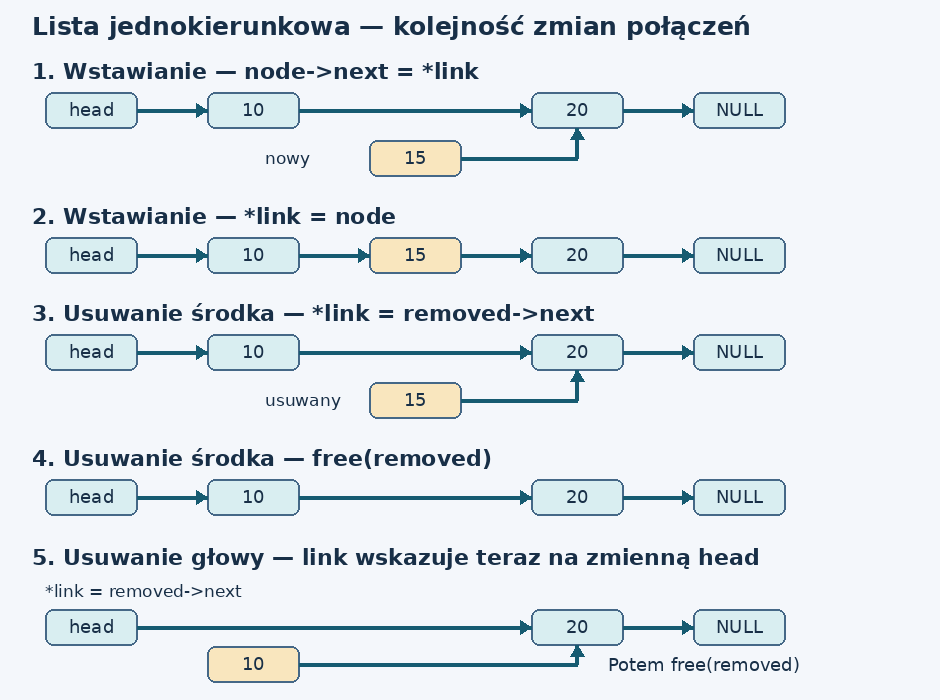

**Przewidź.** Jak zmieni się lista `10 → 20` po wstawieniu `15` za `10`? Jaki zapis wybiera połączenie do usunięcia jej głowy?

In [ ]:
#include <stdio.h>
#include <stdlib.h>

struct Node {
    int value;
    struct Node *next;
};

static struct Node *node_at(struct Node *node, size_t index)
{
    while (node != NULL && index > 0) {
        node = node->next;
        --index;
    }
    return node;
}

static int insert(struct Node **link, int value)
{
    if (link == NULL) {
        return 0;
    }
    struct Node *node = malloc(sizeof *node);
    if (node == NULL) {
        return 0;
    }

    node->value = value;
    node->next = *link;
    *link = node;
    return 1;
}

static int insert_after(struct Node *at, int value)
{
    return at != NULL && insert(&at->next, value);
}

static int erase(struct Node **link)
{
    if (link == NULL || *link == NULL) {
        return 0;
    }
    struct Node *removed = *link;
    *link = removed->next;
    free(removed);
    return 1;
}

static void clear(struct Node **head)
{
    while (erase(head)) {
        /* Każde wywołanie usuwa dotychczasową głowę. */
    }
}

static void print_list(const char *label, const struct Node *node)
{
    printf("%s:", label);
    for (; node != NULL; node = node->next) {
        printf(" %d ->", node->value);
    }
    puts(" NULL");
}

int main(void)
{
    struct Node *head = NULL;
    print_list("Pusta", head);
    if (!insert(&head, 20)) {
        goto allocation_failed;
    }
    print_list("Pierwszy węzeł", head);

    if (!insert(&head, 10)) {
        goto allocation_failed;
    }
    print_list("Po dodaniu głowy", head);

    if (!insert_after(head, 15)) {
        goto allocation_failed;
    }
    print_list("Po wstawieniu 15", head);

    if (!insert_after(node_at(head, 2), 30)) {
        goto allocation_failed;
    }
    print_list("Po dopisaniu 30", head);

    erase(&head->next);
    print_list("Po usunięciu 15", head);
    erase(&head->next->next);
    print_list("Po usunięciu 30", head);
    erase(&head);
    print_list("Po usunięciu głowy", head);

    clear(&head);
    print_list("Po zwolnieniu", head);
    return EXIT_SUCCESS;

allocation_failed:
    clear(&head);
    fputs("Nie udało się przydzielić węzła.\n", stderr);
    return EXIT_FAILURE;
}

Usunięcie `15` łączy bezpośrednio `10` z `20`, a usunięcie ostatniego węzła zapisuje `NULL` w polu `next` jego poprzednika. `erase(&head)` przesuwa głowę. `clear` powtarza ten ostatni krok aż do pustej listy, więc ostatecznie `head == NULL`. W razie nieudanego dodania program przechodzi do wspólnego bloku sprzątania. Wskaźnika do zwolnionego węzła nie można już dereferencjonować.

`node_at` zwraca `NULL` dla pustej listy lub indeksu spoza zakresu. `insert_after(NULL, value)` i `insert(NULL, value)` zwracają `0`. Nieudane `malloc` również daje `0` i pozostawia połączenia bez zmian. `erase` bez istniejącego węzła do usunięcia zwraca `0`. `clear` pustej listy lub z argumentem `NULL` nie ma nic do zrobienia. Jeśli przekazujesz adres pola `next`, wskaźnik do węzła musi nadal wskazywać żywy węzeł. Samo pole `next` może zawierać `NULL`.

**Zmień.** Wstaw `25` po `20`, zanim dopiszesz `30`. Które indeksy lub połączenia użyte dalej trzeba dostosować? Ustal je przed uruchomieniem.

**Sprawdź.** Dlaczego instrukcja `free(removed)` musi nastąpić po odczytaniu `removed->next`? Porównaj koszt odczytu i-tego elementu w tablicy i na liście. Co zmienia znajomość adresu węzła przy wstawianiu?

## W12.9 — Program integracyjny

Flota przechowuje bieżące dane robotów. Pętla wykonuje krok ruchu dla każdego elementu, a osobna funkcja wypisuje całą flotę przed krokiem i po nim. Dzięki temu od razu widać, które dane zmieniły się w tablicy.

**Przewidź.** Oblicz położenia obu robotów po pół sekundy. Czy któryś zmieni tylko jedną współrzędną?

In [ ]:
#include <stdio.h>

struct Robot {
    char name[50];
    double x, y, vx, vy;
};

static void move_robot(struct Robot *r, double dt)
{
    r->x += r->vx * dt;
    r->y += r->vy * dt;
}

static void print_fleet(const struct Robot fleet[], size_t count)
{
    for (size_t i = 0; i < count; ++i) {
        printf("%s: (%.2f, %.2f)\n", fleet[i].name, fleet[i].x, fleet[i].y);
    }
}

int main(void)
{
    struct Robot fleet[] = {
        {.name = "Bzik", .x = 2.0, .y = -1.0, .vx = 0.5, .vy = 2.0},
        {.name = "Iskra", .x = 1.0, .y = 4.0, .vx = -1.0, .vy = 0.0},
    };
    const size_t count = sizeof fleet / sizeof fleet[0];
    const double dt = 0.5;

    puts("Przed krokiem");
    print_fleet(fleet, count);

    for (size_t i = 0; i < count; ++i) {
        move_robot(&fleet[i], dt);
    }

    puts("Po kroku");
    print_fleet(fleet, count);
    return 0;
}

Bzik przemieścił się o ćwierć jednostki w osi `x` i jedną jednostkę w osi `y`. Iskra zmieniła tylko `x`, bo `vy = 0`. Zmiana elementów tablicy jest widoczna w drugim wywołaniu `print_fleet`, które ma dostęp tylko do odczytu pól.

- **Przewidź.** Co wypisze drugi odczyt, jeśli `dt` wyniesie zero?
- **Znajdź błąd.** Co byłoby nie tak z `move_robot(fleet[i], dt)` i pętlą z warunkiem `i <= count`?
- **Zmień.** Dodaj trzeciego robota i wykonaj dwa kroki. Porównaj z jednym krokiem o podwójnym czasie. Jeżeli flota miałaby być listą, jakie pole węzła zastąpiłoby `int value`?